Plot number of patients per center

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import lydata as ly
usz_blue = '#005ea8'
usz_green = '#00afa5'
usz_red = '#ae0060'
usz_orange = '#f17900'
usz_gray = '#c5d5db'
european_dataset = pd.read_csv("ready_tables/european_comparison_patients.csv", header=[0, 1, 2])
canadian_dataset = pd.read_csv("ready_tables/canadian_comparison_patients.csv", header=[0, 1, 2])

## Analysis of data

In [2]:
abc = pd.read_csv("ready_tables/ABC_evaluation_data.csv", header = [0,1,2])
inc = pd.read_csv("ready_tables/INC_evaluation_data.csv", header = [0,1,2])
mid = pd.read_csv("ready_tables/MID_evaluation_data.csv", header = [0,1,2])
ms = pd.read_csv("ready_tables/MS_evaluation_data.csv", header = [0,1,2])
nov = pd.read_csv("ready_tables/NOV_evaluation_data.csv", header = [0,1,2])
ueo = pd.read_csv("ready_tables/UEO_evaluation_data.csv", header = [0,1,2])
xxi = pd.read_csv("ready_tables/XXI_evaluation_data.csv", header = [0,1,2])

In [3]:
datasets = pd.concat([abc, inc, mid, ms, nov, ueo, xxi], ignore_index = True)
# datasets = pd.concat([abc, inc, mid, ueo, xxi], ignore_index = True)

In [4]:
datasets.replace("not recorded", np.nan, inplace = True)
datasets.replace("unknown", np.nan, inplace = True)

patient                                                          \
        core                                                           
          id                     institution   sex age diagnose_date   
0      ABC_1  Centro Medico ABC Observatorio  male  66    2022-07-18   
1      ABC_2  Centro Medico ABC Observatorio  male  64    2020-05-15   
2      ABC_3  Centro Medico ABC Observatorio  male  52    2024-09-27   
3      ABC_4  Centro Medico ABC Observatorio  male  61    2018-09-18   
4      ABC_5  Centro Medico ABC Observatorio  male  58    2020-10-13   
..       ...                             ...   ...  ..           ...   
127  XX I-12             CMN Siglo XXI  Onco  male  61    2022-10-27   
128  XX I-13             CMN Siglo XXI  Onco  male  61    2023-07-17   
129  XX I-15             CMN Siglo XXI  Onco  male  64    2019-01-20   
130  XX I-16             CMN Siglo XXI  Onco  male  75    2018-02-18   
131  XX I-17             CMN Siglo XXI  Onco  male  70    2019-02-23   

                                                                       ...  \
                                                                       ...   
    alcohol_abuse nicotine_abuse smoking_status pack_years hpv_status  ...   
0           False           True        stopped       15.0        NaN  ...   
1           False          False            NaN        0.0        NaN  ...   
2             NaN            NaN            NaN        0.0       True  ...   
3            True           True        stopped       43.0        NaN  ...   
4           False          False            NaN        0.0        NaN  ...   
..            ...            ...            ...        ...        ...  ...   
127          True          False            NaN        0.0       True  ...   
128          True           True        stopped        7.0      False  ...   
129         False          False            NaN        0.0       True  ...   
130         False          False            NaN        0.0       True  ...   
131         False          False            NaN        0.0       True  ...   

    positive_dissected               outcome                  \
                contra                  core                   
                    IV    V local_recurrence date_recurrence   
0                  0.0  0.0            False      2024-02-12   
1                  0.0  0.0            False             NaN   
2                  0.0  0.0             True      2025-07-04   
3                  0.0  0.0             True      2019-06-06   
4                  0.0  0.0            False             NaN   
..                 ...  ...              ...             ...   
127                0.0  0.0            False              NO   
128                0.0  0.0            False              NO   
129                0.0  0.0            False              NO   
130                0.0  0.0            False              NO   
131                0.0  0.0            False              NO   

                                                                            \
                                                                             
                                    recurrence_comment date_last_follow_up   
0    left lung metastasis, surgical resection 24/ju...          2025-05-15   
1                                                  NaN          2026-06-17   
2                  Progresion local y regional (PETRM)          2025-07-04   
3    Clivus derecho, recibio  SRS 25Gy/5fr hasta 28...          2019-10-15   
4                                                  NaN          2021-11-30   
..                                                 ...                 ...   
127                                                 NO                  NO   
128                                                 NO                  NO   
129                                                 NO                  NO   
130                                                 NO                

In [5]:
def to_bool(value):
    if isinstance(value, str):
        normalized = value.strip().casefold()
        if normalized == "true":
            return True
        if normalized == "false":
            return False
    return value

datasets = datasets.map(to_bool)

enhanced_datasets = datasets.ly.enhance()

In [6]:
non_empty_rows = enhanced_datasets['max_llh'].notna().any(axis = 1)
dataset_filled = enhanced_datasets[non_empty_rows]
dataset_empty = enhanced_datasets[~non_empty_rows]

### Final consensus check
Compare your prepared `max_llh` with the enhanced diagnostic consensus at all main
and sublevels. Only known pairs count. The summary and evidence remain available
as DataFrames; raw evidence comes from `datasets`, including sublevel-only FNA.

In [7]:
from scripts import data_checks as checks
from scripts.notebook_display import comparison_view, show_table

levels = tuple(dataset_filled["max_llh"].columns.get_level_values(1).unique())
sources = {name: checks.observations(dataset_filled, name, levels=levels)
           for name in ["max_llh", "diagnostic_consensus"]}
comparisons = [("max_llh", "diagnostic_consensus")]
consensus_summary = checks.comparison_summary(sources, comparisons)
show_table(comparison_view(consensus_summary), percentages=["Agreement"])

disagreement_report = checks.disagreement_details(
    datasets.loc[dataset_filled.index], sources, comparisons,
    subdivisions={"I": ("Ia", "Ib"), "II": ("IIa", "IIb"), "V": ("Va", "Vb")},
)
show_table(disagreement_report[["row", "patient_id", "side", "level", "max_llh",
                                "diagnostic_consensus", "raw_modalities"]],
           binary=["max_llh", "diagnostic_consensus"])

Comparison,Known pairs,Disagreements,Patients affected,Agreement
max_llh vs diagnostic_consensus,3050,3,3,99.9%


row,patient_id,side,level,max_llh,diagnostic_consensus,raw_modalities
115,UEO-3,ipsi,Ib,+,−,CT Ib −; MRI Ib −; PET Ib −; FNA Ib −
116,UEO-4,ipsi,II,−,+,"CT II +, IIa +, IIb +; MRI II −, IIa −, IIb −; PET II +, IIa +, IIb +; FNA II −, IIa −, IIb +"
117,UEO-5,ipsi,II,−,+,"CT II +, IIa +, IIb +; MRI II −, IIa −, IIb −; PET II −, IIa +, IIb −; FNA II +, IIa +, IIb −"


will be used like this for the time being

### Final parent/sublevel check
Check the prepared labels across all modalities and `max_llh`. Flag a negative
parent with a positive child, or a positive parent with both children known negative.
Missing observations alone do not count as contradictions.

In [8]:
hierarchy_report = checks.hierarchy_conflicts(
    dataset_filled, modalities=(*checks.MODALITIES, "max_llh"),
    subdivisions={"I": ("Ia", "Ib"), "II": ("IIa", "IIb"), "V": ("Va", "Vb")},
)
show_table(hierarchy_report, binary=["parent_value"])

row,patient_id,modality,side,level,parent_value,sublevels
115,UEO-3,max_llh,ipsi,I,−,"Ia=False, Ib=True"
116,UEO-4,max_llh,ipsi,II,−,"IIa=False, IIb=True"
117,UEO-5,max_llh,ipsi,II,−,"IIa=False, IIb=True"


In [9]:
dataset_filled['patient','core','institution'].value_counts()

(patient, core, institution)
INCAN                                    54
UMAE Merida                              34
CMN Siglo XXI  Onco                      14
Centro Medico ABC Observatorio            9
CMN20MV                                   8
CMN20GN                                   5
Unidad de Especialidades de Oncología     4
Medica Sur                                1
Name: count, dtype: int64

## Datanalysis

In [10]:
from collections import namedtuple

LNLS = ["I", "II", "III", "IV", "V", "VII"][::-1]
COLORS = {
    "green": "#00afa5",
    "blue": "#005ea8", 
    "gray": "#c5d5db",
    "orange": "#f17900",
    "red": "#ae0060",
}
lyDataColumns = namedtuple("lyDataColumns", ["t_stage", "location", "midext", "subsite"])
COLS = lyDataColumns(
    t_stage=("tumor", "core", "t_stage"),
    location=("tumor", "core", "location"),
    midext=("tumor", "core", "extension"),
    subsite=("tumor", "core", "subsite"),
)
WIDTH = 0.5
OFFSET = WIDTH / 2

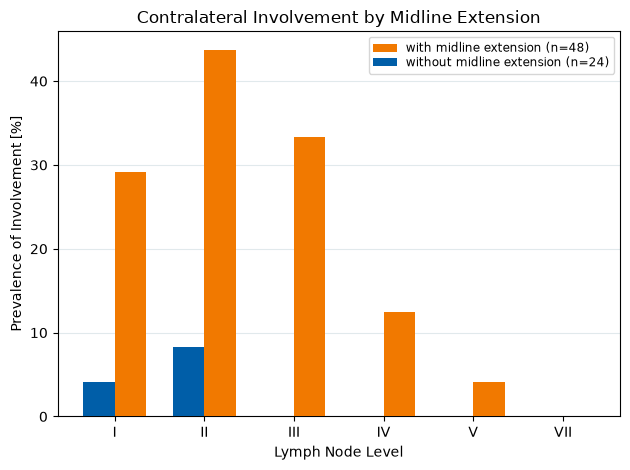

In [11]:
import numpy as np
import matplotlib.pyplot as plt

side = "contra"
levels = list(LNLS)

data = dataset_filled["max_llh", side][levels].astype("Float64")
midline = dataset_filled["tumor", "core", "extension"].astype("boolean")

# Mean of True/False values gives the fraction involved, excluding missing values.
prevalence = (
    data.groupby(midline)
    .mean()
    .mul(100)
    .reindex([False, True])
    .astype(float)
)

fig, axes = plt.subplots()

positions = np.arange(len(levels))
width = 0.35

axes.bar(
    positions - width / 2,
    prevalence.loc[True],
    width=width,
    color=COLORS["orange"],
    label=f"with midline extension (n={midline.eq(True).sum()})",
    zorder=10,
)
axes.bar(
    positions + width / 2,
    prevalence.loc[False],
    width=width,
    color=COLORS["blue"],
    label=f"without midline extension (n={midline.eq(False).sum()})",
    zorder=10,
)

axes.invert_xaxis()
axes.set_xticks(positions)
axes.set_xticklabels(levels)
axes.set_xlabel("Lymph Node Level")
axes.set_ylabel("Prevalence of Involvement [%]")
axes.set_ylim(bottom=0)
axes.grid(axis="y", alpha=0.5, color=COLORS["gray"])

side_label = "Contralateral" if side == "contra" else "Ipsilateral"
axes.set_title(f"{side_label} Involvement by Midline Extension")
axes.legend(labelspacing=0.15, fontsize="small")

fig.tight_layout()
plt.show()

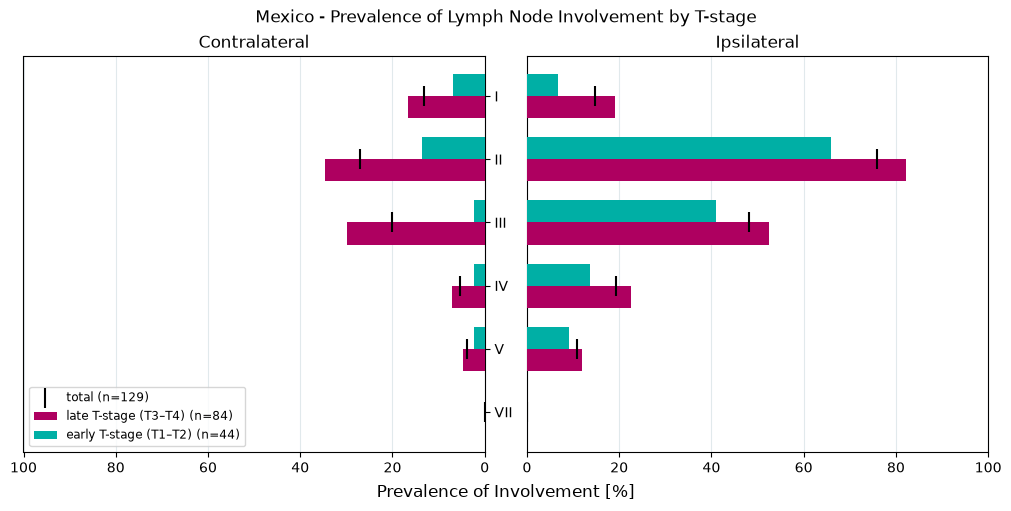

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = dataset_filled
levels = list(LNLS)
t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")

cohorts = [
    ("late T-stage (T3–T4)", t_stage.isin([3, 4]), COLORS["red"]),
    ("early T-stage (T1–T2)", t_stage.isin([1, 2]), COLORS["green"]),
]

fig, axes = plt.subplots(
    1, 2, figsize=(10, 5), sharey=True, layout="constrained"
)

positions = np.arange(len(levels))
height = 0.35

for ax, side, title in zip(
    axes, ["contra", "ipsi"], ["Contralateral", "Ipsilateral"]
):
    involvement = data["max_llh", side][levels].astype("Float64")

    for offset, (label, mask, color) in zip(
        [-height / 2, height / 2], cohorts
    ):
        prevalence = involvement.loc[mask].mean().mul(100).astype(float)

        ax.barh(
            positions + offset,
            prevalence,
            height=height,
            color=color,
            label=f"{label} (n={mask.sum()})",
            zorder=10,
        )

    ax.scatter(
        involvement.mean().mul(100).astype(float),
        positions,
        marker="|",
        s=200,
        color="black",
        label=f"total (n={len(data)})",
        zorder=11,
    )

    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.grid(axis="x", alpha=0.5, color=COLORS["gray"])

# Mirror the panels and show level names between them.
axes[0].invert_xaxis()
axes[0].yaxis.tick_right()
axes[0].set_yticks(positions, labels=levels)
axes[1].tick_params(axis="y", left=False, labelleft=False)

axes[0].legend(loc="lower left", fontsize="small")
fig.supxlabel("Prevalence of Involvement [%]")
fig.suptitle("Mexico - Prevalence of Lymph Node Involvement by T-stage")

# fig.savefig("early_late_contra_and_ipsi.png", dpi=300, bbox_inches="tight")
plt.show()

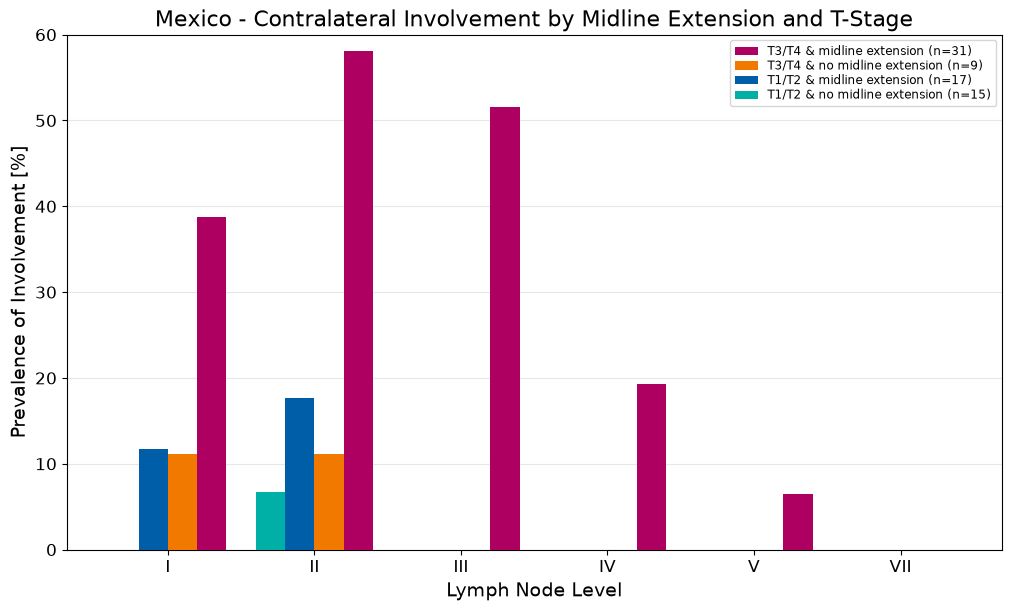

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

side = "contra"

data = dataset_filled
levels = list(LNLS)
involvement = data["max_llh", side][levels].astype("Float64")

t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")
midline = data["tumor", "core", "extension"].astype("boolean")

early_stage = t_stage.isin([1, 2])
late_stage = t_stage.isin([3, 4])

cohorts = [
    (
        "T3/T4 & midline extension",
        late_stage & midline.eq(True),
        COLORS["red"],
    ),
    (
        "T3/T4 & no midline extension",
        late_stage & midline.eq(False),
        COLORS["orange"],
    ),
    (
        "T1/T2 & midline extension",
        early_stage & midline.eq(True),
        COLORS["blue"],
    ),
    (
        "T1/T2 & no midline extension",
        early_stage & midline.eq(False),
        COLORS["green"],
    ),
]

fig, axes = plt.subplots(figsize=(10, 6), layout="constrained")

positions = np.arange(len(levels)) * 1.75
width = 0.35

for i, (label, mask, color) in enumerate(cohorts):
    prevalence = involvement.loc[mask].mean().mul(100).astype(float)

    axes.bar(
        positions + (i - 1.5) * width,
        prevalence,
        width=width,
        color=color,
        label=f"{label} (n={mask.sum()})",
        zorder=10,
    )

axes.invert_xaxis()
axes.set_xticks(positions, labels=levels)
axes.set_xlabel("Lymph Node Level", fontsize=14)
axes.set_ylabel("Prevalence of Involvement [%]", fontsize=14)
axes.set_ylim([0,60])
axes.tick_params(axis="both", labelsize=12)
axes.grid(axis="y", alpha=0.5, color=COLORS["gray"])

side_label = "Contralateral" if side == "contra" else "Ipsilateral"
axes.set_title(
    f"Mexico - {side_label} Involvement by Midline Extension and T-Stage",
    fontsize=16,
)
axes.legend(labelspacing=0.15, fontsize="small")

fig.savefig("Figure_2.png", dpi=300, bbox_inches="tight")
plt.show()

## Comparison European Data

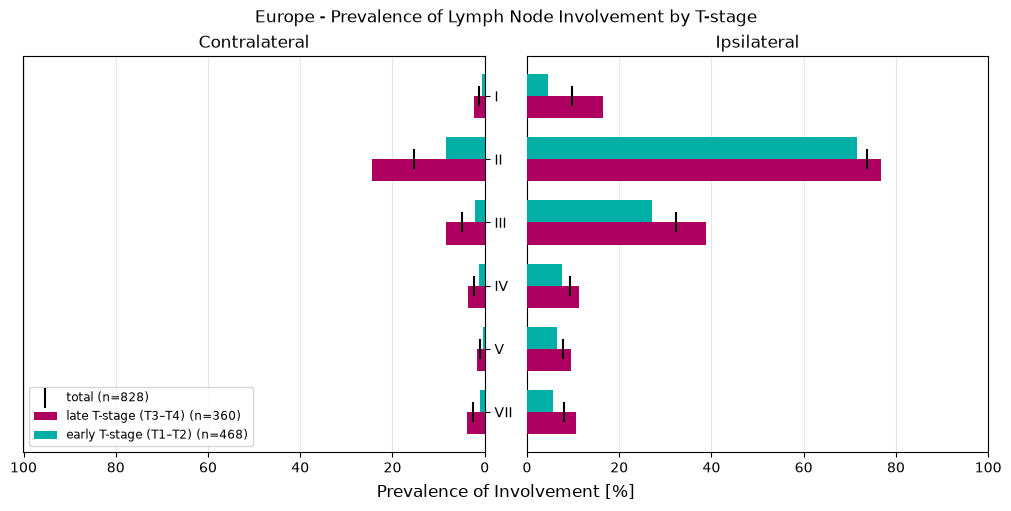

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = european_dataset
levels = list(LNLS)
t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")

cohorts = [
    ("late T-stage (T3–T4)", t_stage.isin([3, 4]), COLORS["red"]),
    ("early T-stage (T1–T2)", t_stage.isin([1, 2]), COLORS["green"]),
]

fig, axes = plt.subplots(
    1, 2, figsize=(10, 5), sharey=True, layout="constrained"
)

positions = np.arange(len(levels))
height = 0.35

for ax, side, title in zip(
    axes, ["contra", "ipsi"], ["Contralateral", "Ipsilateral"]
):
    involvement = data["max_llh", side][levels].astype("Float64")

    for offset, (label, mask, color) in zip(
        [-height / 2, height / 2], cohorts
    ):
        prevalence = involvement.loc[mask].mean().mul(100).astype(float)

        ax.barh(
            positions + offset,
            prevalence,
            height=height,
            color=color,
            label=f"{label} (n={mask.sum()})",
            zorder=10,
        )

    ax.scatter(
        involvement.mean().mul(100).astype(float),
        positions,
        marker="|",
        s=200,
        color="black",
        label=f"total (n={len(data)})",
        zorder=11,
    )

    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.grid(axis="x", alpha=0.5, color=COLORS["gray"])

# Mirror the panels and show level names between them.
axes[0].invert_xaxis()
axes[0].yaxis.tick_right()
axes[0].set_yticks(positions, labels=levels)
axes[1].tick_params(axis="y", left=False, labelleft=False)

axes[0].legend(loc="lower left", fontsize="small")
fig.supxlabel("Prevalence of Involvement [%]")
fig.suptitle("Europe - Prevalence of Lymph Node Involvement by T-stage")

# fig.savefig("early_late_contra_and_ipsi.png", dpi=300, bbox_inches="tight")
plt.show()

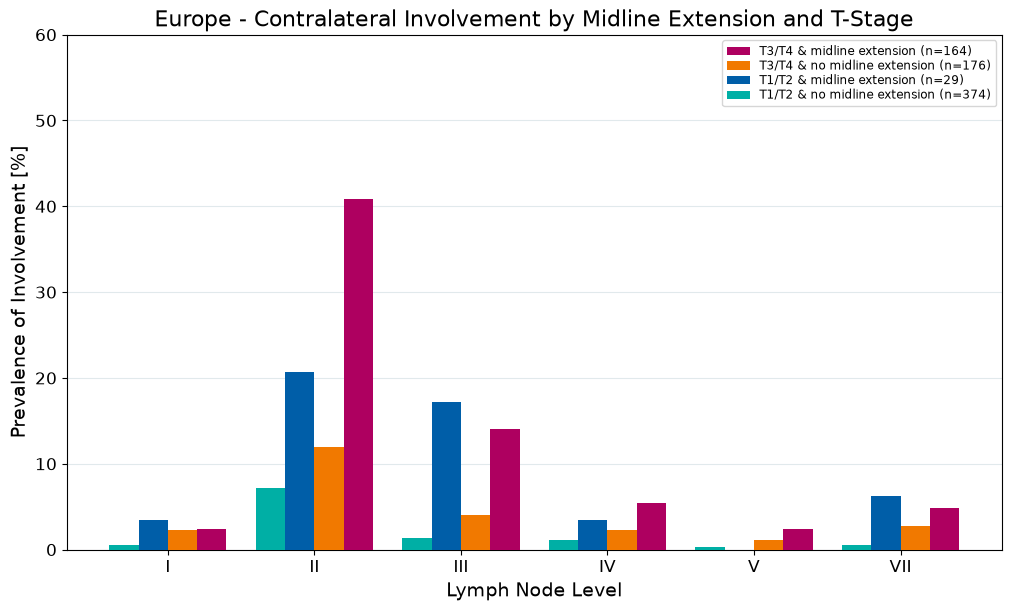

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

side = "contra"

data = european_dataset
levels = list(LNLS)
involvement = data["max_llh", side][levels].astype("Float64")

t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")
midline = data["tumor", "core", "extension"].astype("boolean")

early_stage = t_stage.isin([1, 2])
late_stage = t_stage.isin([3, 4])

cohorts = [
    (
        "T3/T4 & midline extension",
        late_stage & midline.eq(True),
        COLORS["red"],
    ),
    (
        "T3/T4 & no midline extension",
        late_stage & midline.eq(False),
        COLORS["orange"],
    ),
    (
        "T1/T2 & midline extension",
        early_stage & midline.eq(True),
        COLORS["blue"],
    ),
    (
        "T1/T2 & no midline extension",
        early_stage & midline.eq(False),
        COLORS["green"],
    ),
]

fig, axes = plt.subplots(figsize=(10, 6), layout="constrained")

positions = np.arange(len(levels)) * 1.75
width = 0.35

for i, (label, mask, color) in enumerate(cohorts):
    prevalence = involvement.loc[mask].mean().mul(100).astype(float)

    axes.bar(
        positions + (i - 1.5) * width,
        prevalence,
        width=width,
        color=color,
        label=f"{label} (n={mask.sum()})",
        zorder=10,
    )

axes.invert_xaxis()
axes.set_xticks(positions, labels=levels)
axes.set_xlabel("Lymph Node Level", fontsize=14)
axes.set_ylabel("Prevalence of Involvement [%]", fontsize=14)
axes.set_ylim([0,60])
axes.tick_params(axis="both", labelsize=12)
axes.grid(axis="y", alpha=0.5, color=COLORS["gray"])

side_label = "Contralateral" if side == "contra" else "Ipsilateral"
axes.set_title(
    f"Europe - {side_label} Involvement by Midline Extension and T-Stage",
    fontsize=16,
)
axes.legend(labelspacing=0.15, fontsize="small")

fig.savefig("Figure_2.png", dpi=300, bbox_inches="tight")
plt.show()

## Comparison Canadian Data

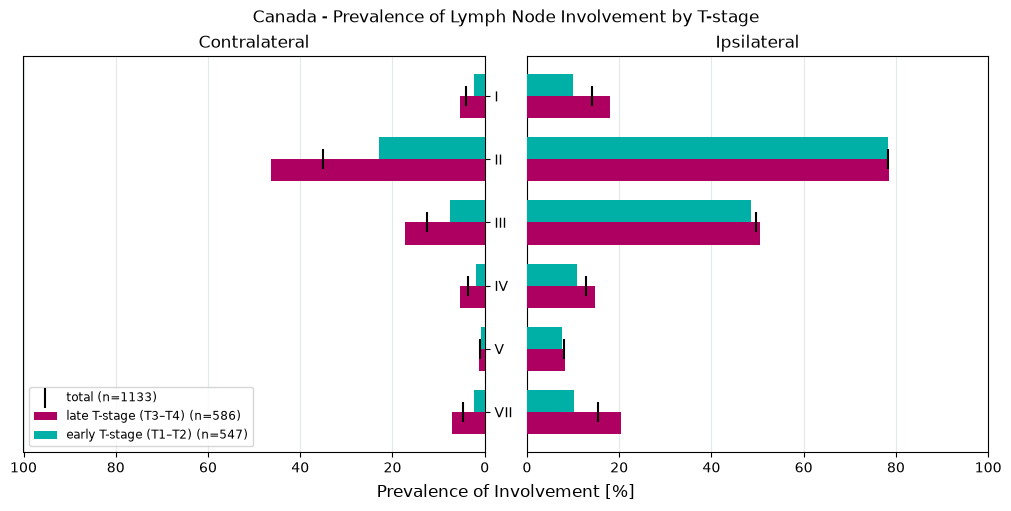

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = canadian_dataset
levels = list(LNLS)
t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")

cohorts = [
    ("late T-stage (T3–T4)", t_stage.isin([3, 4]), COLORS["red"]),
    ("early T-stage (T1–T2)", t_stage.isin([1, 2]), COLORS["green"]),
]

fig, axes = plt.subplots(
    1, 2, figsize=(10, 5), sharey=True, layout="constrained"
)

positions = np.arange(len(levels))
height = 0.35

for ax, side, title in zip(
    axes, ["contra", "ipsi"], ["Contralateral", "Ipsilateral"]
):
    involvement = data["max_llh", side][levels].astype("Float64")

    for offset, (label, mask, color) in zip(
        [-height / 2, height / 2], cohorts
    ):
        prevalence = involvement.loc[mask].mean().mul(100).astype(float)

        ax.barh(
            positions + offset,
            prevalence,
            height=height,
            color=color,
            label=f"{label} (n={mask.sum()})",
            zorder=10,
        )

    ax.scatter(
        involvement.mean().mul(100).astype(float),
        positions,
        marker="|",
        s=200,
        color="black",
        label=f"total (n={len(data)})",
        zorder=11,
    )

    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.grid(axis="x", alpha=0.5, color=COLORS["gray"])

# Mirror the panels and show level names between them.
axes[0].invert_xaxis()
axes[0].yaxis.tick_right()
axes[0].set_yticks(positions, labels=levels)
axes[1].tick_params(axis="y", left=False, labelleft=False)

axes[0].legend(loc="lower left", fontsize="small")
fig.supxlabel("Prevalence of Involvement [%]")
fig.suptitle("Canada - Prevalence of Lymph Node Involvement by T-stage")

# fig.savefig("early_late_contra_and_ipsi.png", dpi=300, bbox_inches="tight")
plt.show()

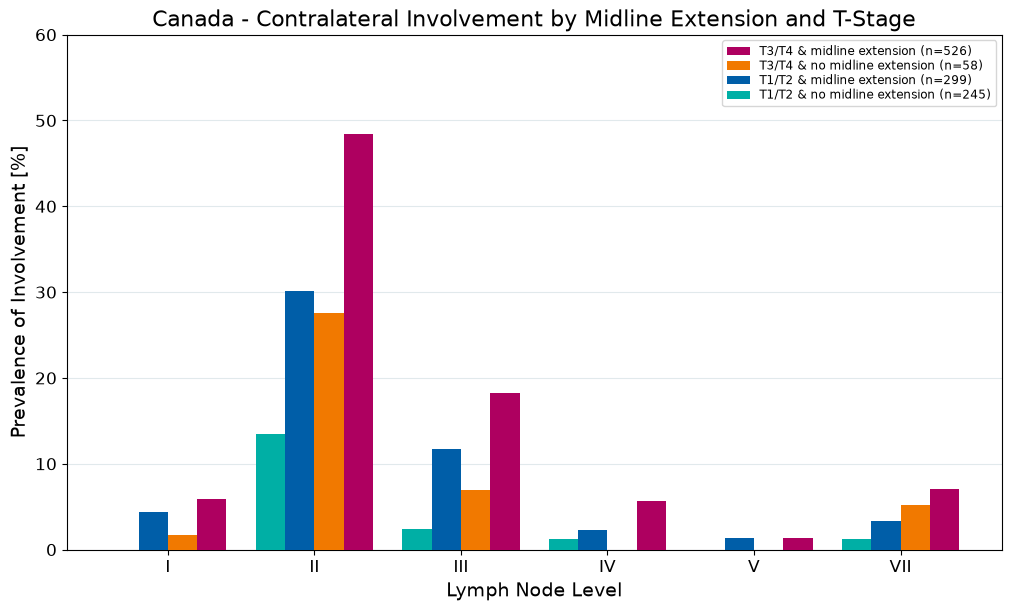

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

side = "contra"

data = canadian_dataset
levels = list(LNLS)
involvement = data["max_llh", side][levels].astype("Float64")

t_stage = pd.to_numeric(data["tumor", "core", "t_stage"], errors="coerce")
midline = data["tumor", "core", "extension"].astype("boolean")

early_stage = t_stage.isin([1, 2])
late_stage = t_stage.isin([3, 4])

cohorts = [
    (
        "T3/T4 & midline extension",
        late_stage & midline.eq(True),
        COLORS["red"],
    ),
    (
        "T3/T4 & no midline extension",
        late_stage & midline.eq(False),
        COLORS["orange"],
    ),
    (
        "T1/T2 & midline extension",
        early_stage & midline.eq(True),
        COLORS["blue"],
    ),
    (
        "T1/T2 & no midline extension",
        early_stage & midline.eq(False),
        COLORS["green"],
    ),
]

fig, axes = plt.subplots(figsize=(10, 6), layout="constrained")

positions = np.arange(len(levels)) * 1.75
width = 0.35

for i, (label, mask, color) in enumerate(cohorts):
    prevalence = involvement.loc[mask].mean().mul(100).astype(float)

    axes.bar(
        positions + (i - 1.5) * width,
        prevalence,
        width=width,
        color=color,
        label=f"{label} (n={mask.sum()})",
        zorder=10,
    )

axes.invert_xaxis()
axes.set_xticks(positions, labels=levels)
axes.set_xlabel("Lymph Node Level", fontsize=14)
axes.set_ylabel("Prevalence of Involvement [%]", fontsize=14)
axes.set_ylim([0,60])
axes.tick_params(axis="both", labelsize=12)
axes.grid(axis="y", alpha=0.5, color=COLORS["gray"])

side_label = "Contralateral" if side == "contra" else "Ipsilateral"
axes.set_title(
    f"Canada - {side_label} Involvement by Midline Extension and T-Stage",
    fontsize=16,
)
axes.legend(labelspacing=0.15, fontsize="small")

fig.savefig("Figure_2.png", dpi=300, bbox_inches="tight")
plt.show()